<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/20_fuego/21_fuego_sarimax.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 21 · Modelo SARIMA / SARIMAX del fuego mensual en la Altillanura

**Autora:** Michelle

**Pregunta:** ¿cuánto del fuego mensual explican la lluvia y El Niño, y cuánto fuego esperar en la temporada seca dic 2026 – mar 2027?

**Entradas** (`datos/comunes/`):
- `firms_mensual_municipio.csv` (cuaderno 03)
- `chirps_mensual_municipio.csv` (cuaderno 11)
- `oni_mensual.csv` (cuaderno 10)
- `altillanura_municipios.csv` (cuaderno 01)

**Salidas:**
- `modulos/clima_fuego/resultados/21_*.csv`: métricas, rejilla, pronósticos, escenarios y coeficientes.
- `modulos/clima_fuego/graficas/21_*.png`

**Modelos:** naive estacional y climatología (referencias), SARIMA, SARIMAX con anomalía de lluvia (explicativo) y SARIMAX con ONI rezagado (para pronosticar).

**Validación:** entrenamiento 2003–2021 y prueba 2022–2025 con origen rodante. Las métricas se reportan con y sin 2024–2025, por la deriva del satélite Terra.

## Paso 1. Preparar el entorno

In [ ]:
# Rutas del proyecto: funcionan en Colab y en local (ver 00_configuracion)
import os, sys, subprocess
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    # Los datos crudos pesados (MGN, CSV de FIRMS, copia del ONI) siguen en Drive
    CRUDOS = '/content/drive/MyDrive/proyecto-altillanura-STDG/datos/crudos'
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        !git clone -q {REPO} {RAIZ}
    # Mientras el PR #3 no esté unido a main, los datos comunes están en esta rama
    if not os.path.exists(f'{RAIZ}/datos/comunes/oni_mensual.csv'):
        !git -C {RAIZ} fetch -q origin feature/clima-fuego-datos
        !git -C {RAIZ} checkout -q feature/clima-fuego-datos
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))   # el cuaderno está en notebooks/<etapa>/
    CRUDOS = os.path.join(RAIZ, 'datos', 'crudos')

COMUNES = os.path.join(RAIZ, 'datos', 'comunes')
GRAFICAS = os.path.join(RAIZ, 'modulos', 'clima_fuego', 'graficas')
os.makedirs(GRAFICAS, exist_ok=True)

def traer(ruta):
    """Baja de DVC un archivo pesado del repo (por ejemplo un .gpkg) si todavía no está."""
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

print('Raíz del repo:', RAIZ)
print('Crudos:', CRUDOS, '| existe:', os.path.exists(CRUDOS))

RESULTADOS = os.path.join(RAIZ, 'modulos', 'clima_fuego', 'resultados')
os.makedirs(RESULTADOS, exist_ok=True)

import warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
warnings.filterwarnings('ignore')

Mounted at /content/drive
Raíz del repo: /content/Proyecto-ALTILLANURA
Crudos: /content/drive/MyDrive/proyecto-altillanura-STDG/datos/crudos | existe: True


## Paso 2. Armar las series regionales
- **Fuego:** suma de focos de los 7 municipios, enero 2003 – diciembre 2025 (Terra + Aqua). Se modela `log(1 + focos)` para estabilizar la varianza.
- **Lluvia:** anomalía mensual respecto a la normal 1991–2020, promediada por municipio y ponderada por área.
- **ONI:** índice mensual de NOAA.

In [ ]:
firms = pd.read_csv(f'{COMUNES}/firms_mensual_municipio.csv', dtype={'mpio_cdpmp': str})
firms['fecha'] = pd.PeriodIndex(firms['mes'], freq='M').to_timestamp()
focos = (firms.groupby('fecha')['focos_total'].sum()
              .asfreq('MS', fill_value=0).loc['2003-01-01':'2025-12-01'])
focos.name = 'focos'

chirps = pd.read_csv(f'{COMUNES}/chirps_mensual_municipio.csv', dtype={'mpio_cdpmp': str})
areas = pd.read_csv(f'{COMUNES}/altillanura_municipios.csv', dtype={'mpio_cdpmp': str}).set_index('mpio_cdpmp')['area_km2']
chirps['fecha'] = pd.PeriodIndex(chirps['mes'], freq='M').to_timestamp()
chirps['w'] = chirps['mpio_cdpmp'].map(areas)
pond = lambda col: chirps.assign(v=chirps[col] * chirps['w']).groupby('fecha')['v'].sum() / chirps.groupby('fecha')['w'].sum()
lluvia_anom = pond('anom_mm').asfreq('MS'); lluvia_anom.name = 'lluvia_anom_mm'

oni = pd.read_csv(f'{COMUNES}/oni_mensual.csv', parse_dates=['fecha']).set_index('fecha')['oni'].asfreq('MS')

y = np.log1p(focos)
print('Meses de fuego:', len(focos), '|', focos.index.min().date(), 'a', focos.index.max().date())
print('Meses sin lluvia (debe ser 0):', lluvia_anom.reindex(focos.index).isna().sum())
print('Último ONI disponible:', oni.dropna().index.max().date(), '=', oni.dropna().iloc[-1])

Meses de fuego: 276 | 2003-01-01 a 2025-12-01
Meses sin lluvia (debe ser 0): 0
Último ONI disponible: 2026-09-01 = 2.46


## Paso 3. Identificación: descomposición STL y estacionariedad
Se prueba ADF (H0: no estacionaria) y KPSS (H0: estacionaria) con y sin diferencias. `d` y `D` se fijan **antes** de comparar modelos, porque el AICc solo compara modelos con la misma diferenciación.

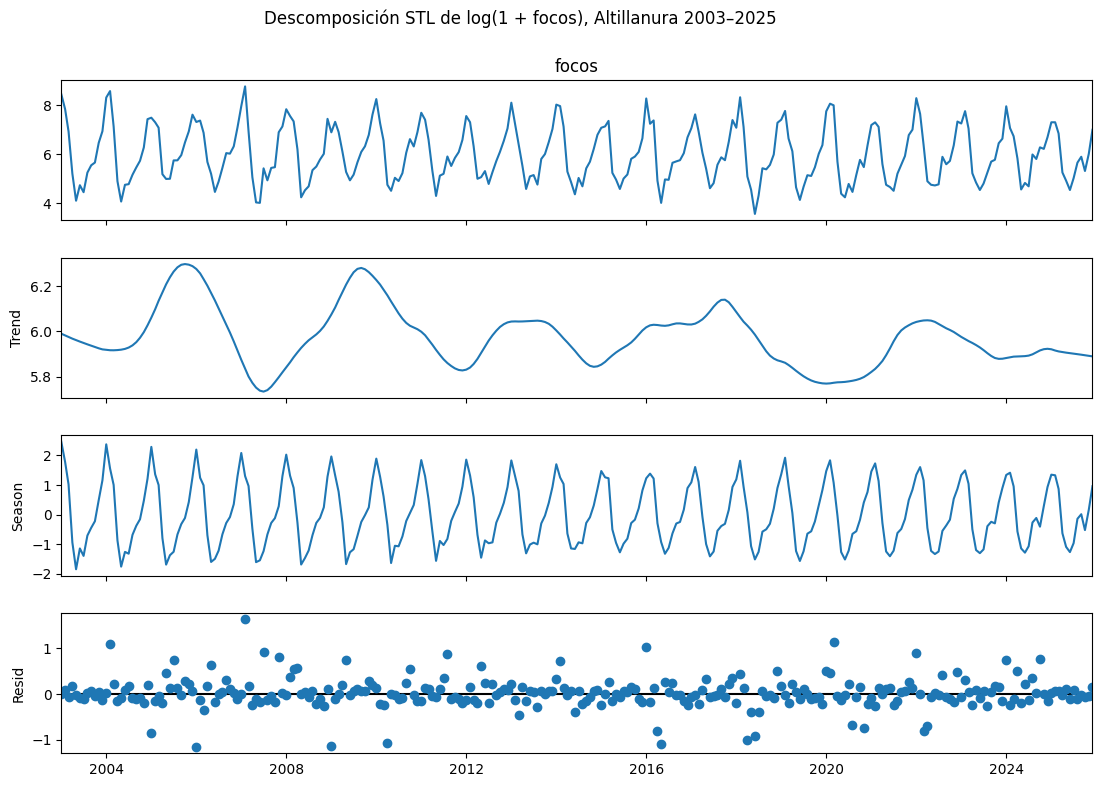

Fuerza de la estacionalidad: 0.91 | fuerza de la tendencia: 0.09
 d  D  p_ADF  p_KPSS  estacionaria
 0  0  0.007     0.1          True
 0  1  0.000     0.1          True
 1  0  0.000     0.1          True
 1  1  0.000     0.1          True

Diferenciación elegida: d = 0, D = 1


In [ ]:
stl = STL(y, period=12, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(12, 8)
fig.suptitle('Descomposición STL de log(1 + focos), Altillanura 2003–2025', y=1.01)
plt.savefig(f'{GRAFICAS}/21_stl.png', dpi=150, bbox_inches='tight'); plt.show()
fuerza_est = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
fuerza_ten = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
print(f'Fuerza de la estacionalidad: {fuerza_est:.2f} | fuerza de la tendencia: {fuerza_ten:.2f}')

def pruebas(s):
    s = s.dropna()
    return adfuller(s, autolag='AIC')[1], kpss(s, regression='c', nlags='auto')[1]

filas = []
for d, D in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    s = y.copy()
    if D: s = s.diff(12)
    if d: s = s.diff(1)
    p_adf, p_kpss = pruebas(s)
    filas.append({'d': d, 'D': D, 'p_ADF': round(p_adf, 3), 'p_KPSS': round(p_kpss, 3),
                  'estacionaria': p_adf < 0.05 and p_kpss >= 0.05})
estac = pd.DataFrame(filas); print(estac.to_string(index=False))
ok = estac[estac['estacionaria']]
d, D = (int(ok.iloc[0]['d']), int(ok.iloc[0]['D'])) if len(ok) else (0, 1)
if fuerza_est > 0.64 and D == 0:
    D = 1   # estacionalidad fuerte: se diferencia estacionalmente
print(f'\nDiferenciación elegida: d = {d}, D = {D}')

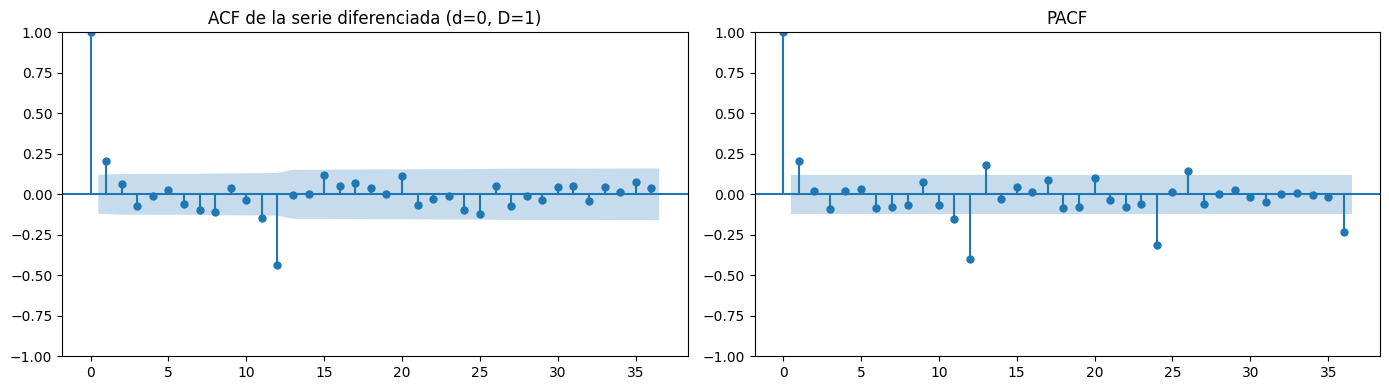

In [ ]:
s = y.copy()
if D: s = s.diff(12)
if d: s = s.diff(1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(s.dropna(), lags=36, ax=ax[0]); plot_pacf(s.dropna(), lags=36, ax=ax[1], method='ywm')
ax[0].set_title(f'ACF de la serie diferenciada (d={d}, D={D})'); ax[1].set_title('PACF')
plt.tight_layout(); plt.savefig(f'{GRAFICAS}/21_acf_pacf.png', dpi=150); plt.show()

## Paso 4. Funciones, periodos y métricas
- **MAE:** error medio en focos por mes (métrica principal).
- **MASE:** MAE dividido entre el error del naive estacional en el entrenamiento; < 1 significa que el modelo le gana a la referencia.
- **MAE dic–mar:** error solo en la temporada de quemas.
- **RMSE:** castiga más los errores grandes.
- **Cobertura 95 %:** fracción de meses reales dentro del intervalo del 95 %.

In [ ]:
FIN_TRAIN = '2021-12-01'
ANIOS_PRUEBA = [2022, 2023, 2024, 2025]
SECOS = [12, 1, 2, 3]

def ajustar(serie, orden, estacional, exog=None):
    tendencia = 'c' if (orden[1] + estacional[1]) == 0 else 'n'
    return SARIMAX(serie, exog=exog, order=orden, seasonal_order=estacional,
                   trend=tendencia).fit(disp=False, maxiter=200)

def metricas(real, pred, lo, hi, escala):
    e = real - pred
    secos = real.index.month.isin(SECOS)
    return pd.Series({'MAE': e.abs().mean(),
                      'MASE': e.abs().mean() / escala,
                      'MAE_dic_mar': e[secos].abs().mean(),
                      'RMSE': np.sqrt((e ** 2).mean()),
                      'cobertura_95': ((real >= lo) & (real <= hi)).mean() if lo is not None else np.nan})

f_train = focos.loc[:FIN_TRAIN]
escala_mase = (f_train - f_train.shift(12)).abs().mean()
print(f'Escala del MASE (error medio del naive estacional en entrenamiento): {escala_mase:.0f} focos/mes')

Escala del MASE (error medio del naive estacional en entrenamiento): 371 focos/mes


## Paso 5. Búsqueda del SARIMA por AICc
Rejilla p, q ∈ {0, 1, 2}; P, Q ∈ {0, 1}, con la `d` y la `D` del paso 3. Se elige el de menor AICc cuyos residuos pasen Ljung-Box en el rezago 12 (p > 0,05).

In [ ]:
y_train = y.loc[:FIN_TRAIN]
resultados = []
for p, q, P, Q in itertools.product([0, 1, 2], [0, 1, 2], [0, 1], [0, 1]):
    try:
        r = ajustar(y_train, (p, d, q), (P, D, Q, 12))
        resultados.append({'orden': (p, d, q), 'estacional': (P, D, Q, 12), 'AICc': r.aicc,
                           'LB12_p': acorr_ljungbox(r.resid[13:], lags=[12])['lb_pvalue'].iloc[0]})
    except Exception as e:
        pass
rejilla = pd.DataFrame(resultados).sort_values('AICc').reset_index(drop=True)
print(rejilla.head(8).round(3).to_string())
validos = rejilla[rejilla['LB12_p'] > 0.05]
mejor = (validos if len(validos) else rejilla).iloc[0]
ORDEN, ESTACIONAL = mejor['orden'], mejor['estacional']
print(f'\nModelo elegido: SARIMA{ORDEN}x{ESTACIONAL}  (AICc = {mejor["AICc"]:.1f})')

       orden     estacional     AICc  LB12_p
0  (1, 0, 0)  (0, 1, 1, 12)  242.344   0.565
1  (1, 0, 0)  (1, 1, 1, 12)  243.108   0.610
2  (0, 0, 2)  (0, 1, 1, 12)  243.265   0.619
3  (0, 0, 2)  (1, 1, 1, 12)  244.012   0.659
4  (2, 0, 0)  (0, 1, 1, 12)  244.351   0.560
5  (0, 0, 1)  (0, 1, 1, 12)  244.357   0.431
6  (1, 0, 1)  (0, 1, 1, 12)  244.375   0.563
7  (2, 0, 2)  (0, 1, 1, 12)  244.952   0.826

Modelo elegido: SARIMA(1, 0, 0)x(0, 1, 1, 12)  (AICc = 242.3)


## Paso 6. Variables externas: lluvia y ONI
- **SARIMAX lluvia (explicativo):** usa la anomalía de lluvia del mismo mes. Explica el fuego, pero para pronosticar necesita saber la lluvia futura; por eso se usa con escenarios.
- **SARIMAX ONI:** usa el ONI de k meses antes (k = 2, 3 o 4), que ya se conoce al pronosticar. Se elige el rezago con menor AICc.

In [ ]:
x_lluvia = lluvia_anom.reindex(y.index).to_frame()
cands = []
for k in [2, 3, 4]:
    x_k = oni.shift(k).reindex(y_train.index).to_frame(f'oni_rez{k}')
    r = ajustar(y_train, ORDEN, ESTACIONAL, x_k)
    cands.append({'rezago': k, 'AICc': r.aicc, 'coef': r.params[f'oni_rez{k}'], 'p': r.pvalues[f'oni_rez{k}']})
cands = pd.DataFrame(cands); print(cands.round(4).to_string(index=False))
K = int(cands.sort_values('AICc').iloc[0]['rezago'])
x_oni = oni.shift(K).reindex(y.index).to_frame(f'oni_rez{K}')
print(f'\nRezago del ONI elegido: {K} meses')

r_ll = ajustar(y_train, ORDEN, ESTACIONAL, x_lluvia.loc[:FIN_TRAIN])
b, pb = r_ll.params['lluvia_anom_mm'], r_ll.pvalues['lluvia_anom_mm']
lo_b, hi_b = r_ll.conf_int().loc['lluvia_anom_mm']
efecto = lambda c: (np.exp(-10 * c) - 1) * 100
print(f'\nSARIMAX con lluvia: β = {b:.4f} (p = {pb:.4f})')
print(f'Por cada 10 mm menos de lluvia que lo normal, los focos cambian {efecto(b):+.1f} % '
      f'(IC 95 %: {efecto(hi_b):+.1f} % a {efecto(lo_b):+.1f} %)')

 rezago     AICc    coef      p
      2 244.0903  0.0251 0.5318
      3 244.3967  0.0067 0.8673
      4 244.3690 -0.0099 0.8086

Rezago del ONI elegido: 2 meses

SARIMAX con lluvia: β = -0.0063 (p = 0.0000)
Por cada 10 mm menos de lluvia que lo normal, los focos cambian +6.5 % (IC 95 %: +5.4 % a +7.5 %)


## Paso 7. Validación con origen rodante, 2022–2025
Para cada año de prueba, los modelos se ajustan con los datos hasta diciembre del año anterior y pronostican los 12 meses siguientes.

In [ ]:
filas = []
for anio in ANIOS_PRUEBA:
    fin = pd.Timestamp(f'{anio - 1}-12-01')
    idx = pd.date_range(f'{anio}-01-01', periods=12, freq='MS')
    hist = focos.loc[:fin]
    real = focos.loc[idx]
    filas.append(pd.DataFrame({'fecha': idx, 'modelo': 'Naive estacional', 'real': real.values,
                               'pred': hist.loc[idx - pd.DateOffset(years=1)].values, 'lo': np.nan, 'hi': np.nan}))
    clim = hist.groupby(hist.index.month).mean()
    filas.append(pd.DataFrame({'fecha': idx, 'modelo': 'Climatología', 'real': real.values,
                               'pred': clim.loc[idx.month].values, 'lo': np.nan, 'hi': np.nan}))
    for nombre, X in [('SARIMA', None), ('SARIMAX lluvia (explicativo)', x_lluvia), (f'SARIMAX ONI rezago {K}', x_oni)]:
        r = ajustar(y.loc[:fin], ORDEN, ESTACIONAL, None if X is None else X.loc[:fin])
        fc = r.get_forecast(12, exog=None if X is None else X.loc[idx])
        ci = fc.conf_int(alpha=0.05)
        filas.append(pd.DataFrame({'fecha': idx, 'modelo': nombre, 'real': real.values,
                                   'pred': np.expm1(fc.predicted_mean.values),
                                   'lo': np.expm1(ci.iloc[:, 0].values), 'hi': np.expm1(ci.iloc[:, 1].values)}))
pron = pd.concat(filas, ignore_index=True).set_index('fecha')

def tabla(datos):
    out = {}
    for m, g in datos.groupby('modelo', sort=False):
        lo = None if g['lo'].isna().all() else g['lo']
        out[m] = metricas(g['real'], g['pred'], lo, g['hi'], escala_mase)
    return pd.DataFrame(out).T

t_todo = tabla(pron)
t_sin = tabla(pron[pron.index.year <= 2023])
print('Prueba 2022–2025 (origen rodante, 12 meses adelante):')
print(t_todo.round(2).to_string())
print('\nPrueba 2022–2023 (sin los años afectados por la deriva de Terra):')
print(t_sin.round(2).to_string())

Prueba 2022–2025 (origen rodante, 12 meses adelante):
                                 MAE  MASE  MAE_dic_mar    RMSE  cobertura_95
Naive estacional              335.67  0.91       838.00  666.21           NaN
Climatología                  219.72  0.59       541.21  408.02           NaN
SARIMA                        207.13  0.56       505.99  409.16          1.00
SARIMAX lluvia (explicativo)  178.44  0.48       366.60  342.48          0.83
SARIMAX ONI rezago 2          209.90  0.57       514.88  413.34          1.00

Prueba 2022–2023 (sin los años afectados por la deriva de Terra):
                                 MAE  MASE  MAE_dic_mar    RMSE  cobertura_95
Naive estacional              395.00  1.07      1051.38  803.79           NaN
Climatología                  206.58  0.56       539.17  426.21           NaN
SARIMA                        219.74  0.59       581.70  481.99          1.00
SARIMAX lluvia (explicativo)  213.96  0.58       470.83  440.37          0.79
SARIMAX ONI rezago 2 

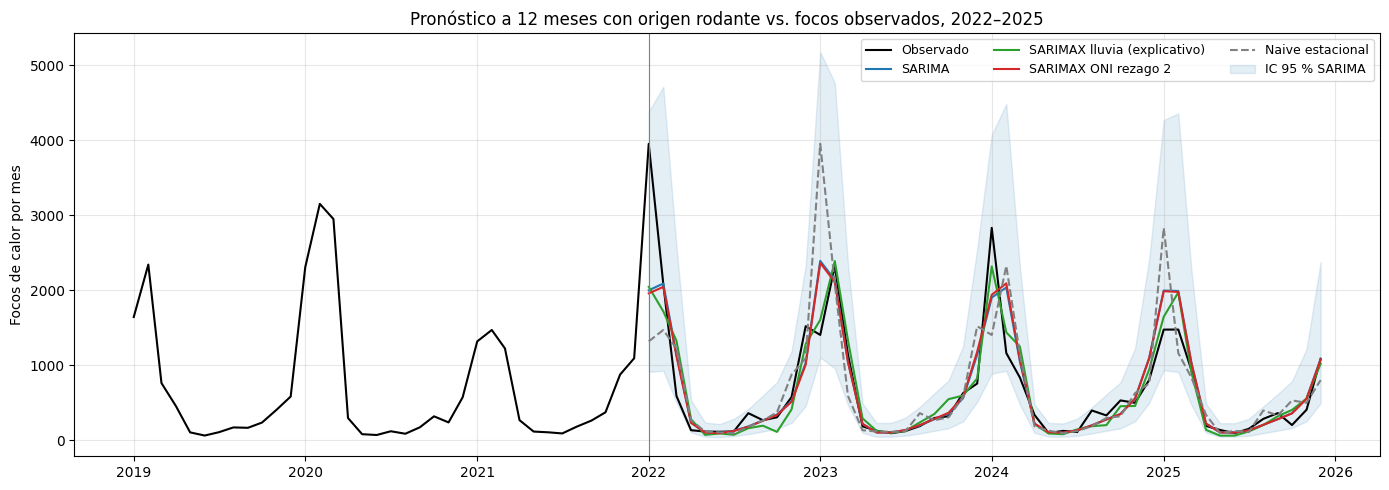

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(focos.loc['2019':], color='black', linewidth=1.5, label='Observado')
estilos = {'SARIMA': 'tab:blue', 'SARIMAX lluvia (explicativo)': 'tab:green', f'SARIMAX ONI rezago {K}': 'tab:red',
           'Naive estacional': 'gray'}
for m, c in estilos.items():
    g = pron[pron['modelo'] == m]
    ax.plot(g.index, g['pred'], color=c, linestyle='--' if m == 'Naive estacional' else '-', label=m)
g = pron[pron['modelo'] == 'SARIMA']
ax.fill_between(g.index, g['lo'], g['hi'], color='tab:blue', alpha=0.12, label='IC 95 % SARIMA')
ax.axvline(pd.Timestamp('2022-01-01'), color='gray', linewidth=0.8)
ax.set_title('Pronóstico a 12 meses con origen rodante vs. focos observados, 2022–2025')
ax.set_ylabel('Focos de calor por mes'); ax.legend(ncol=3, fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{GRAFICAS}/21_validacion.png', dpi=150); plt.show()

## Paso 8. Modelos finales (2003–2025) y diagnóstico de residuos
Ljung-Box en los rezagos 12 y 24: p > 0,05 indica que los residuos son ruido blanco.

SARIMA                     AICc =   273.9 | Ljung-Box p (12) = 0.596, p (24) = 0.799
SARIMAX lluvia             AICc =   187.2 | Ljung-Box p (12) = 0.900, p (24) = 0.962
SARIMAX ONI rezago 2       AICc =   275.7 | Ljung-Box p (12) = 0.620, p (24) = 0.809


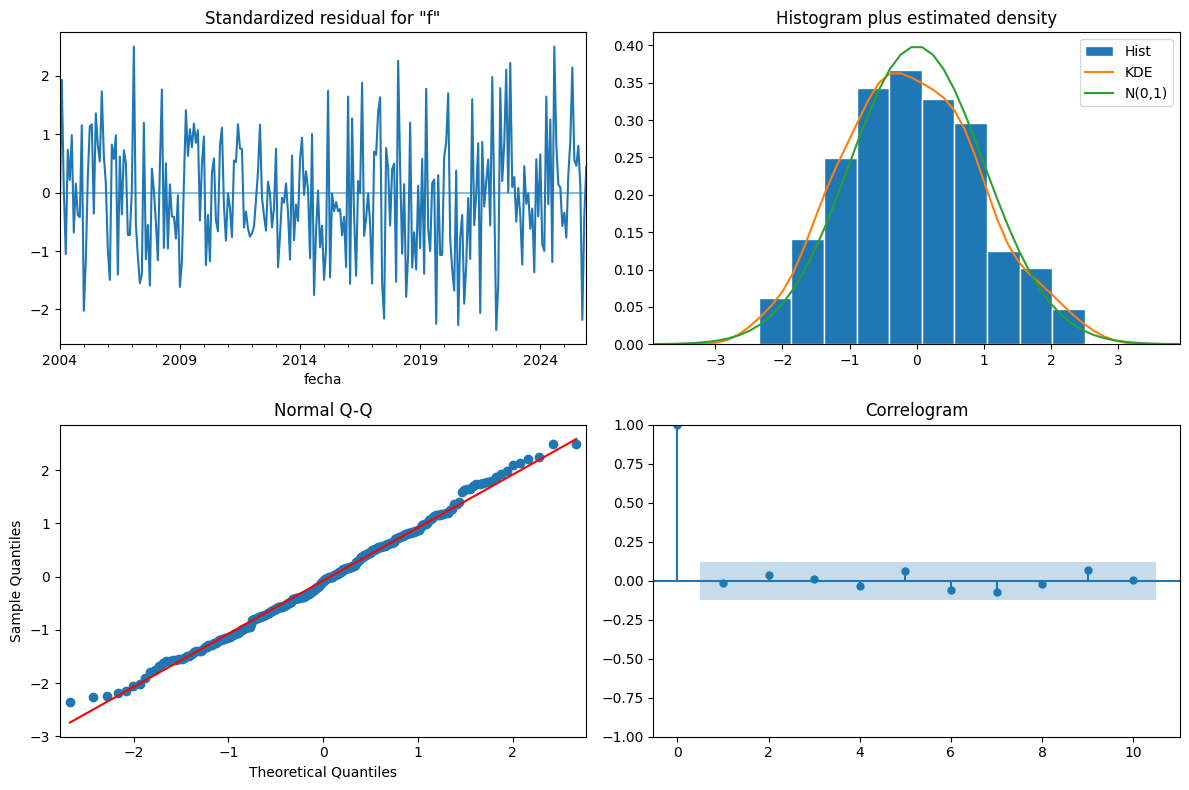

In [ ]:
finales = {'SARIMA': None, 'SARIMAX lluvia': x_lluvia, f'SARIMAX ONI rezago {K}': x_oni}
modelos = {}
for nombre, X in finales.items():
    r = ajustar(y, ORDEN, ESTACIONAL, X)
    modelos[nombre] = r
    lb = acorr_ljungbox(r.resid[13:], lags=[12, 24])['lb_pvalue'].values
    print(f'{nombre:26s} AICc = {r.aicc:7.1f} | Ljung-Box p (12) = {lb[0]:.3f}, p (24) = {lb[1]:.3f}')
fig = modelos['SARIMAX lluvia'].plot_diagnostics(figsize=(12, 8))
plt.tight_layout(); plt.savefig(f'{GRAFICAS}/21_diagnostico_sarimax_lluvia.png', dpi=150); plt.show()

## Paso 9. Escenarios para la temporada seca dic 2026 – mar 2027
Los datos de fuego llegan hasta diciembre de 2025, así que se pronostica de enero 2026 a marzo 2027.
- **Lluvia:** de enero a noviembre de 2026 se supone anomalía 0. En dic–mar se usa la mediana, el percentil 25 o el percentil 10 de la anomalía de ese mes en 1991–2025.
- **El Niño persistente:** el último ONI conocido se mantiene constante hacia adelante.

**Advertencias:** el pronóstico probablemente está sesgado a la baja, porque 2024–2025 tienen menos detecciones por la deriva de Terra. Los intervalos de la temporada son aproximados.

In [ ]:
ref = lluvia_anom.loc['1991':'2025']
pct = ref.groupby(ref.index.month).quantile
escenarios = {'Normal (mediana)': pct(0.50), 'Seco (percentil 25)': pct(0.25), 'Muy seco (percentil 10)': pct(0.10)}
idx_f = pd.date_range('2026-01-01', '2027-03-01', freq='MS')
temporada = idx_f[idx_f >= '2026-12-01']
salidas = []
r = modelos['SARIMAX lluvia']
for nombre, q in escenarios.items():
    x_f = pd.DataFrame({'lluvia_anom_mm': np.where(idx_f.isin(temporada), q.loc[idx_f.month].values, 0.0)}, index=idx_f)
    fc = r.get_forecast(len(idx_f), exog=x_f); ci = fc.conf_int(alpha=0.05)
    salidas.append(pd.DataFrame({'fecha': idx_f, 'escenario': nombre, 'lluvia_anom_mm': x_f.iloc[:, 0].values,
                                 'focos_pred': np.expm1(fc.predicted_mean.values),
                                 'focos_lo95': np.expm1(ci.iloc[:, 0].values), 'focos_hi95': np.expm1(ci.iloc[:, 1].values)}))
oni_ult = oni.dropna()
oni_f = oni.reindex(oni.index.union(idx_f)).copy()
oni_f.loc[oni_f.index > oni_ult.index.max()] = oni_ult.iloc[-1]
x_of = oni_f.shift(K).reindex(idx_f).to_frame(f'oni_rez{K}')
fc = modelos[f'SARIMAX ONI rezago {K}'].get_forecast(len(idx_f), exog=x_of); ci = fc.conf_int(alpha=0.05)
salidas.append(pd.DataFrame({'fecha': idx_f, 'escenario': f'El Niño persistente (ONI = {oni_ult.iloc[-1]:+.2f})',
                             'lluvia_anom_mm': np.nan, 'focos_pred': np.expm1(fc.predicted_mean.values),
                             'focos_lo95': np.expm1(ci.iloc[:, 0].values), 'focos_hi95': np.expm1(ci.iloc[:, 1].values)}))
esc = pd.concat(salidas, ignore_index=True)
resumen = (esc[esc['fecha'].isin(temporada)].groupby('escenario', sort=False)
           [['focos_pred', 'focos_lo95', 'focos_hi95']].sum().round(0))
hist_temp = focos[focos.index.month.isin(SECOS)]
anio_t = np.where(hist_temp.index.month == 12, hist_temp.index.year + 1, hist_temp.index.year)
hist_temp = hist_temp.groupby(anio_t).sum().loc[2004:2025]
print('Focos esperados en la temporada dic 2026 – mar 2027:')
print(resumen.to_string())
print(f'\nReferencia: promedio 2004–2025 = {hist_temp.mean():.0f} focos por temporada '
      f'(mínimo {hist_temp.min():.0f}, máximo {hist_temp.max():.0f})')
print('Nota: los intervalos de la suma son aproximados (se suman los límites mensuales).')

Focos esperados en la temporada dic 2026 – mar 2027:
                                   focos_pred  focos_lo95  focos_hi95
escenario                                                            
Normal (mediana)                       6081.0      3079.0     12007.0
Seco (percentil 25)                    6538.0      3310.0     12908.0
Muy seco (percentil 10)                6977.0      3533.0     13774.0
El Niño persistente (ONI = +2.46)      6431.0      2954.0     13998.0

Referencia: promedio 2004–2025 = 6813 focos por temporada (mínimo 4577, máximo 11574)
Nota: los intervalos de la suma son aproximados (se suman los límites mensuales).


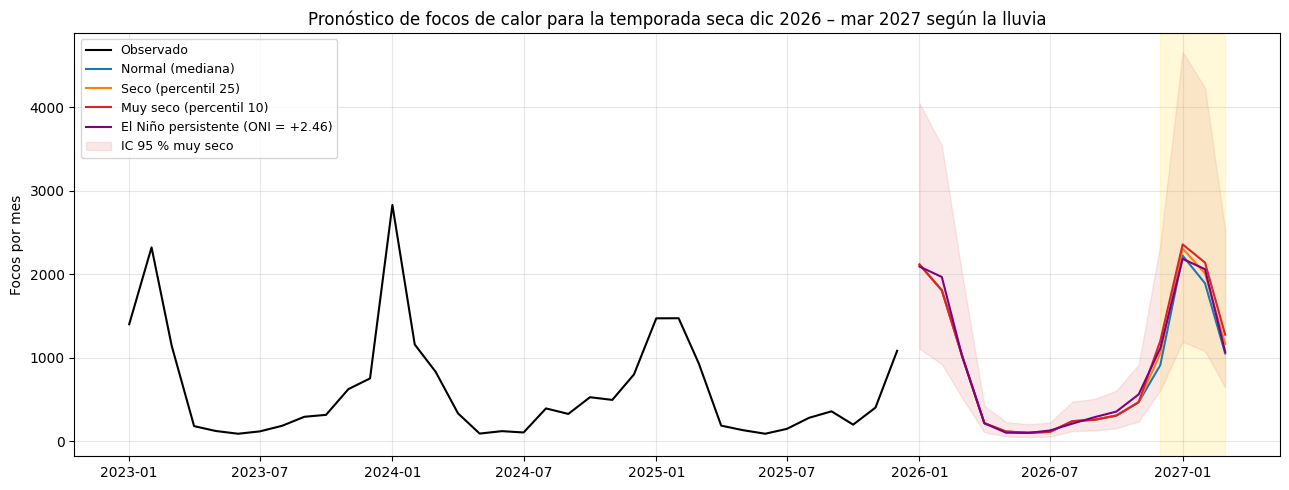

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(focos.loc['2023':], color='black', label='Observado')
colores = ['tab:blue', 'tab:orange', 'tab:red', 'purple']
for (nombre, g), c in zip(esc.groupby('escenario', sort=False), colores):
    ax.plot(g['fecha'], g['focos_pred'], color=c, label=nombre)
g = esc[esc['escenario'] == 'Muy seco (percentil 10)']
ax.fill_between(g['fecha'], g['focos_lo95'], g['focos_hi95'], color='tab:red', alpha=0.1, label='IC 95 % muy seco')
ax.axvspan(pd.Timestamp('2026-12-01'), pd.Timestamp('2027-03-01'), color='gold', alpha=0.15)
ax.set_title('Pronóstico de focos de calor para la temporada seca dic 2026 – mar 2027 según la lluvia')
ax.set_ylabel('Focos por mes'); ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{GRAFICAS}/21_escenarios_2026_2027.png', dpi=150); plt.show()

## Paso 10. Guardar resultados

In [ ]:
t_todo.round(3).to_csv(f'{RESULTADOS}/21_metricas_2022_2025.csv')
t_sin.round(3).to_csv(f'{RESULTADOS}/21_metricas_2022_2023.csv')
rejilla.to_csv(f'{RESULTADOS}/21_rejilla_sarima.csv', index=False)
pron.reset_index().to_csv(f'{RESULTADOS}/21_pronosticos_validacion.csv', index=False)
esc.to_csv(f'{RESULTADOS}/21_escenarios_2026_2027.csv', index=False)
coefs = pd.concat({n: pd.DataFrame({'coef': m.params, 'p': m.pvalues}) for n, m in modelos.items()})
coefs.round(5).to_csv(f'{RESULTADOS}/21_coeficientes.csv')
print('Guardado en', RESULTADOS); print(sorted(os.listdir(RESULTADOS)))

if EN_COLAB:   # descarga resultados y gráficas en un ZIP para subirlos al repo desde Git Bash
    import shutil
    from google.colab import files
    shutil.make_archive('/content/resultados_21', 'zip', os.path.join(RAIZ, 'modulos', 'clima_fuego'))
    files.download('/content/resultados_21.zip')

Guardado en /content/Proyecto-ALTILLANURA/modulos/clima_fuego/resultados
['21_coeficientes.csv', '21_escenarios_2026_2027.csv', '21_metricas_2022_2023.csv', '21_metricas_2022_2025.csv', '21_pronosticos_validacion.csv', '21_rejilla_sarima.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>